In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Agriculture.csv')

In [3]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
df.shape

(2200, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [6]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [9]:
df['label'].value_counts()


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

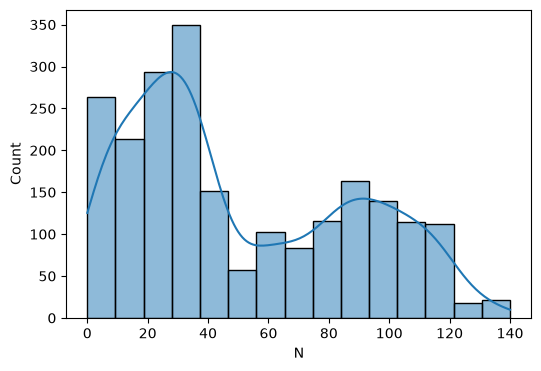

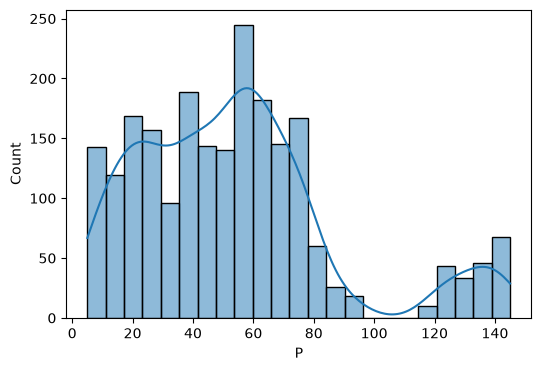

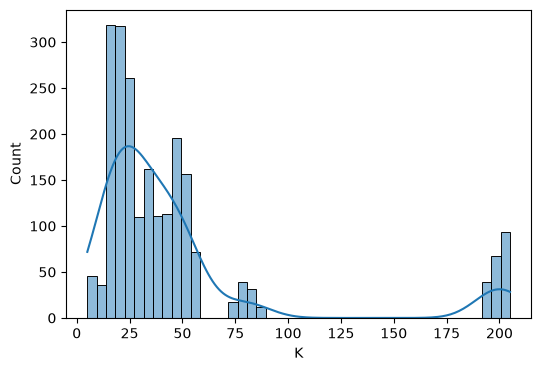

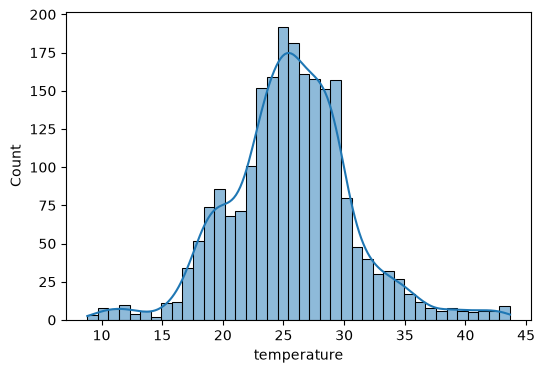

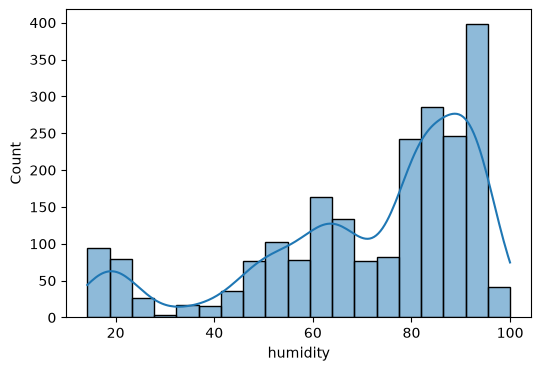

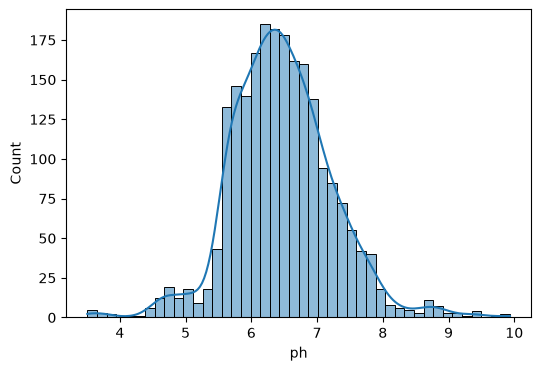

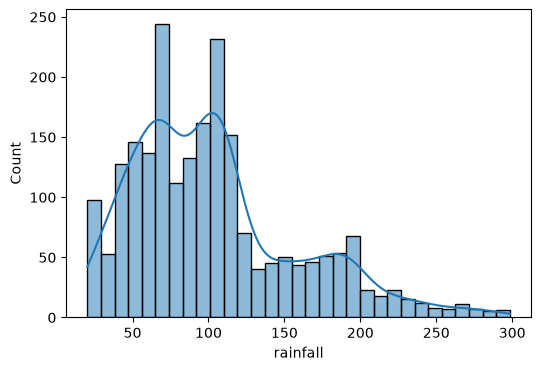

In [10]:
numeric_columns = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True)

In [11]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df['label'] = encoder.fit_transform(df['label'])

In [12]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,20
1,85,58,41,21.770462,80.319644,7.038096,226.655537,20
2,60,55,44,23.004459,82.320763,7.840207,263.964248,20
3,74,35,40,26.491096,80.158363,6.980401,242.864034,20
4,78,42,42,20.130175,81.604873,7.628473,262.717340,20


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

In [14]:
X = df.drop('label', axis=1)
y = df['label']

In [15]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [16]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [17]:
print("Training set :", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set     :", X_test.shape, y_test.shape)

Training set : (1540, 7) (1540,)
Validation set: (330, 7) (330,)
Test set     : (330, 7) (330,)


In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [19]:
models = {
    'Logistic Regression' : LogisticRegression(),
    'KNN' : KNeighborsClassifier(),
    'Naive Bayes' : GaussianNB(),
    'Decision Tree' : DecisionTreeClassifier(),
    'SVM' : SVC()
}

In [20]:
results = []

In [21]:
for name, model in models.items():

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Validation prediction
    y_val_pred = model.predict(X_val_scaled)

    # Test prediction
    y_test_pred = model.predict(X_test_scaled)

    # Validation metrics
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted')
   
    # Test metrics
    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average='weighted')
    
    # Store results
    results.append({
        "Model": name,
        "Validation Accuracy": round(val_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Validation F1 Score": round(val_f1, 4),
        "Test F1 Score": round(test_f1, 4)
    })

In [22]:
results_df = pd.DataFrame(results)
results_df.sort_values(by="Test Accuracy", ascending=False)

,Model,Validation Accuracy,Test Accuracy,Validation F1 Score,Test F1 Score
2,Naive Bayes,0.9939,0.9909,0.9939,0.9909
4,SVM,0.9909,0.9879,0.9909,0.9878
3,Decision Tree,0.9788,0.9848,0.9788,0.9847
0,Logistic Regression,0.9667,0.9788,0.9665,0.9787
1,KNN,0.9848,0.9727,0.9848,0.9724


In [23]:
results_validation = []
for name, model in models.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_val_pred = model.predict(X_val_scaled)
    y_test_pred = model.predict(X_test_scaled)

    # Accuracy
    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    # Difference between train and validation
    gap = train_acc - val_acc

    # Check model fitting
    if train_acc < 0.90 and val_acc < 0.90:
        status = "Underfitting"
    elif gap > 0.05:
        status = "Overfitting"
    else:
        status = "Good Fit"

    results_validation.append({
        "Model": name,
        "Train Accuracy": round(train_acc, 4),
        "Validation Accuracy": round(val_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Gap (Train-Val)": round(gap, 4),
        "Status": status
    })


In [26]:
results_validation_df = pd.DataFrame(results_validation)
results_validation_df.sort_values(by="Test Accuracy", ascending=False)

,Model,Train Accuracy,Validation Accuracy,Test Accuracy,Gap (Train-Val),Status
2,Naive Bayes,0.9955,0.9939,0.9909,0.0015,Good Fit
4,SVM,0.9818,0.9909,0.9879,-0.0091,Good Fit
3,Decision Tree,1.0000,0.9727,0.9848,0.0273,Good Fit
0,Logistic Regression,0.9747,0.9667,0.9788,0.0080,Good Fit
1,KNN,0.9818,0.9848,0.9727,-0.0030,Good Fit


In [25]:
# import joblib

# joblib.dump(models['Naive Bayes'], 'Naive_Bayes_agrimind.pkl')
# joblib.dump(scaler, 'scaler_agrimind.pkl')
# joblib.dump(X.columns.tolist(), 'columns_agrimind.pkl')
# joblib.dump(encoder, 'label_encoder_agrimind.pkl')